# Calculate single perturbation score per variant

We want one overall edgotyping score to make variant-level hit calls. Here we explore several strategies for this:

- call the variant "perturbed" if any edge is perturbed
- compute the fraction of perturbed edges and find some way to calibrate this score
- calculate the Euclidean distance between profiles and find some way to calibrate this score

# Automated

In [35]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
import os

In [36]:
outputs_dir = "../3_outputs/sqY2H"
meta_outputs = "../../../1_allele_collection/3_outputs"

In [37]:
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv

# Calculate Euclidean distance for each variant relative to it's wildtype reference
orf_profiles = [f for f in os.listdir(f"{outputs_dir}/edgotype_profiles/auto_summed") if "_auto_summed" in f]

zero_col = "0"
perturbed_thresh = 0.5 # edge called "perturbed" if >= 50% decrease compared to wt reference
orf_distances = []

wt_thresh = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

for orf in orf_profiles:
    profiles = pl.read_csv(f"{outputs_dir}/edgotype_profiles/auto_summed/{orf}")
    
    # filter out edges where the WT could not be measured
    profiles = profiles.filter(~pl.col("0").is_null())

    db_orf_id = orf.replace("orf_id_", "")
    db_orf_id = db_orf_id.replace("_auto_summed.csv", "")

    columns = [col for col in profiles.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profiles_filled = profiles.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profiles_filled[col] - profiles_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())

        # Cosine similarity
        wt = profiles_filled.select(zero_col).to_numpy()
        var = profiles_filled.select(col).to_numpy()

        # Add to your distance calculation loop
        max_perturbation = (profiles_filled[zero_col] - profiles_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profiles_filled[zero_col] / profiles_filled[col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profiles_filled[zero_col] - profiles_filled[col]) / profiles_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else None
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        # Node removal detection metrics
        perturbations = profiles_filled[col] - profiles_filled[zero_col]
        relative_perturbations = perturbations / profiles_filled[zero_col]

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.8  # 80% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()

        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profiles_filled[col].min()
        min_relative_edge_value = (profiles_filled[col] / profiles_filled[zero_col]).min()


        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim

        # calculate frac perturbed
        wt_pass = []
        per_edges = []
        # for thresh in wt_thresh:
        #     filt_wt = profiles.filter(pl.col("0") > thresh)
        #     wt_pass.append(filt_wt.shape[0])
        #     per_edges.append(filt_wt.filter((pl.col(col)/pl.col("0")) <= perturbed_thresh).shape[0])   
            
            # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profiles
            profile_matrix = profiles_filled.select([col for col in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profiles_filled.select(zero_col).to_numpy().flatten()
            var_profile = profiles_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            

        distance_rows.append({
            "db_orf_id": db_orf_id,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            # "cosine_distance": cos_dist,
            "num_edges": profiles.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value
            # "num_zero_wt": profiles.filter(pl.col("0") == 0).shape[0],
            # "num_per_0.0": per_edges[0],
            # "num_per_0.1": per_edges[1],
            # "num_per_0.2": per_edges[2],
            # "num_per_0.3": per_edges[3],
            # "num_per_0.4": per_edges[4],
            # "num_per_0.5": per_edges[5],
            # "num_edge_0.0": wt_pass[0],
            # "num_edge_0.1": wt_pass[1],
            # "num_edge_0.2": wt_pass[2],
            # "num_edge_0.3": wt_pass[3],
            # "num_edge_0.4": wt_pass[4],
            # "num_edge_0.5": wt_pass[5],
            # "frac_per_0.0": per_edges[0]/wt_pass[0] if wt_pass[0] != 0 else None,
            # "frac_per_0.1": per_edges[1]/wt_pass[1] if wt_pass[1] != 0 else None,
            # "frac_per_0.2": per_edges[2]/wt_pass[2] if wt_pass[2] != 0 else None,
            # "frac_per_0.3": per_edges[3]/wt_pass[3] if wt_pass[3] != 0 else None,
            # "frac_per_0.4": per_edges[4]/wt_pass[4] if wt_pass[4] != 0 else None,
            # "frac_per_0.5": per_edges[5]/wt_pass[5] if wt_pass[5] != 0 else None
        })


    result_profiles = pl.DataFrame(distance_rows)
    orf_distances.append(result_profiles)

# concatentate and normalize wrt dimensionality
orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_51598/315999929.py:97: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)


In [44]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
"""9866""","""216927""",2800.120564,2263.146439,0.806754,2263.146439,5.174751,5.174751,2.37149,2.37149,null,2,false,0.5,-1956.018998,-0.638325,0.238195,542.103276,0.193246,1979.984239,null,0.208022,"""ZMYND10""","""Val16Gly""","""47T>G""","""ENSG00000004838""","""CEGS2""","""1_Pathogenic""",null,2.0,"""ZMYND10_Val16Gly"""
"""9866""","""216928""",3443.1497,2761.011839,0.786825,2761.011839,4.690973,4.690973,2.229887,2.229887,null,2,false,0.0,-2409.10855,-0.760083,0.037818,748.044454,0.213175,2434.674502,null,0.255793,"""ZMYND10""","""Leu266Pro""","""797T>C""","""ENSG00000004838""","""CEGS2""","""1_Pathogenic""",null,1.0,"""ZMYND10_Leu266Pro"""
"""5442""","""215414""",5037.093899,1166.095047,0.144014,1166.095047,1.168243,1.168243,0.22434,0.22434,null,4,false,0.0,1099.962612,0.465683,0.812821,5623.132216,0.855986,2518.54695,null,0.264605,"""SIX1""","""Val106Gly""","""317T>G""","""ENSG00000126778""","""CEGS2""","""5_Others""",null,null,"""SIX1_Val106Gly"""
"""513""","""213754""",3738.170548,2999.526489,0.64197,2999.526489,2.793063,2.793063,1.481848,1.481848,7.823961,3,false,0.0,-191.532342,0.022249,0.646348,1672.851008,0.35803,2158.233772,4.517166,0.226749,"""FA2H""","""Phe144Ser""","""431T>C""","""ENSG00000103089""","""CEGS2""","""1_Pathogenic""",null,null,"""FA2H_Phe144Ser"""
"""513""","""213753""",1195.479709,481.938175,0.103146,481.938175,1.115009,1.115009,0.157055,0.157055,0.74706,3,false,0.0,355.072035,0.116553,0.190276,4190.439322,0.896854,690.210532,0.431315,0.072515,"""FA2H""","""Arg143Cys""","""427C>T""","""ENSG00000103089""","""CEGS2""","""3_Conflicting""",null,1.0,"""FA2H_Arg143Cys"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""3732""","""201256""",330.216994,-330.216994,-0.087135,330.216994,0.919849,0.919849,-0.120531,0.120531,null,1,false,0.0,330.216994,0.087135,null,4119.943874,1.087135,330.216994,null,0.034693,"""UROD""","""Gly281Val""","""842G>T""","""ENSG00000126088""","""CEGS2""","""1_Pathogenic""",0.000008,2.0,"""UROD_Gly281Val"""
"""3732""","""201252""",185.779019,185.779019,0.049022,185.779019,1.051549,1.051549,0.072516,0.072516,null,1,false,0.0,-185.779019,-0.049022,null,3603.947861,0.950978,185.779019,null,0.019518,"""UROD""","""Glu167Lys""","""499G>A""","""ENSG00000126088""","""CEGS2""","""4_VUS""",0.000002,1.0,"""UROD_Glu167Lys"""
"""3732""","""201258""",476.473297,-476.473297,-0.125728,476.473297,0.888314,0.888314,-0.170858,0.170858,null,1,false,0.0,476.473297,0.125728,null,4266.200177,1.125728,476.473297,null,0.050059,"""UROD""","""Tyr311Cys""","""932A>G""","""ENSG00000126088""","""CEGS2""","""3_Conflicting""",0.000003,1.0,"""UROD_Tyr311Cys"""


In [38]:
orf_distances.filter(pl.col("all_edges_severely_perturbed") == True)

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64
"""386""","""213660""",6453.658059,4861.512558,0.951543,4861.512558,20.636944,20.636944,4.367157,4.367157,null,2,true,1.0,-4552.983764,-0.949188,0.00333,216.146409,0.048457,4563.425377
"""386""","""213659""",6185.822889,4818.072036,0.938373,4818.072036,16.226655,16.226655,4.020294,4.020294,null,2,true,1.0,-4348.790298,-0.90405,0.04854,316.423533,0.061627,4374.037312
"""3727""","""214871""",7433.634245,7433.634245,0.886822,7433.634245,8.835638,8.835638,3.143334,3.143334,null,1,true,1.0,-7433.634245,-0.886822,null,948.695439,0.113178,7433.634245
"""100016069""","""2617""",7028.629357,5736.7741,0.868408,5736.7741,7.599268,7.599268,2.92586,2.92586,null,2,true,1.0,-4898.845962,-0.846043,0.031629,869.304587,0.131592,4969.991481
"""100016069""","""2610""",7353.513593,5969.687828,0.903666,5969.687828,10.380537,10.380537,3.375809,3.375809,null,2,true,1.0,-5131.75969,-0.887293,0.023155,636.390859,0.096334,5199.719327
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""70497""","""3791""",4932.184469,4932.184469,0.889929,4932.184469,9.085028,9.085028,3.183491,3.183491,null,1,true,1.0,-4932.184469,-0.889929,null,610.039224,0.110071,4932.184469
"""70497""","""3876""",4484.206685,4484.206685,0.809099,4484.206685,5.238312,5.238312,2.389102,2.389102,null,1,true,1.0,-4484.206685,-0.809099,null,1058.017008,0.190901,4484.206685
"""70497""","""205585""",4792.936092,4792.936092,0.864804,4792.936092,7.396657,7.396657,2.886873,2.886873,null,1,true,1.0,-4792.936092,-0.864804,null,749.2876,0.135196,4792.936092


In [39]:
orf_distances.filter(pl.col("db_orf_id") == '100016069')

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64
"""100016069""","""2617""",7028.629357,5736.7741,0.868408,5736.7741,7.599268,7.599268,2.92586,2.92586,null,2,true,1.0,-4898.845962,-0.846043,0.031629,869.304587,0.131592,4969.991481
"""100016069""","""2644""",1195.418877,726.619643,0.109993,726.619643,1.123586,1.123586,0.168111,0.168111,null,2,false,0.0,111.308495,0.041271,0.213919,5879.459044,0.890007,845.288794
"""100016069""","""2610""",7353.513593,5969.687828,0.903666,5969.687828,10.380537,10.380537,3.375809,3.375809,null,2,true,1.0,-5131.75969,-0.887293,0.023155,636.390859,0.096334,5199.719327
"""100016069""","""2635""",6558.728605,5165.115268,0.81986,5165.115268,5.551235,5.551235,2.472809,2.472809,null,2,false,0.5,-4603.603476,-0.800867,0.026861,888.130727,0.18014,4637.721472
"""100016069""","""2616""",7171.858047,6122.130968,0.926742,6122.130968,13.650397,13.650397,3.770871,3.770871,null,2,false,0.5,-4928.889101,-0.842223,0.119528,483.947719,0.073258,5071.269459
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""100016069""","""2622""",7010.717977,5723.924425,0.866463,5723.924425,7.488575,7.488575,2.904691,2.904691,null,2,true,1.0,-4885.996286,-0.843768,0.032096,882.154262,0.133537,4957.326222
"""100016069""","""2606""",7263.539448,5905.213318,0.893906,5905.213318,9.425603,9.425603,3.236585,3.236585,null,2,true,1.0,-5067.28518,-0.875875,0.0255,700.865369,0.106094,5136.097999
"""100016069""","""2660""",5008.495317,4278.914785,0.647724,4278.914785,2.838682,2.838682,1.505221,1.505221,null,2,false,0.0,-3440.986647,-0.587852,0.084672,2327.163902,0.352276,3541.541002


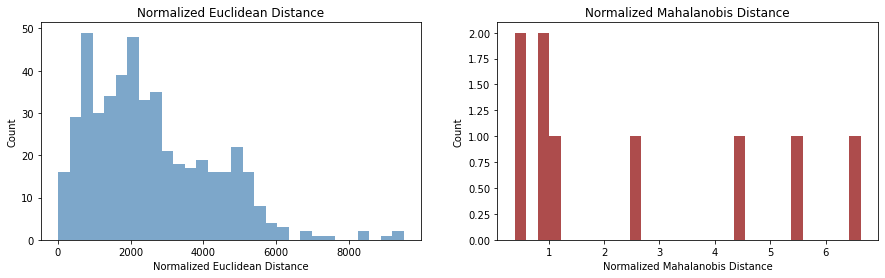

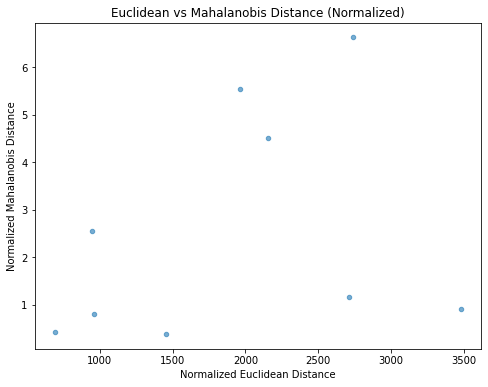

In [40]:
# Add this after your existing normalization
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahalanobis_distance"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

# Plot comparison of normalized distances
fig, axs = plt.subplots(1, 2, figsize=(15, 4))

# Normalized Euclidean Distance
x1 = orf_distances['normalized_euclid_distance']
axs[0].hist(x1, bins=30, color='steelblue', alpha=0.7)
axs[0].set_title("Normalized Euclidean Distance")
axs[0].set_xlabel("Normalized Euclidean Distance")
axs[0].set_ylabel("Count")

# Normalized Mahalanobis Distance
x2 = orf_distances.filter(~pl.col("normalized_mahalanobis_distance").is_null())['normalized_mahalanobis_distance']
axs[1].hist(x2, bins=30, color='darkred', alpha=0.7)
axs[1].set_title("Normalized Mahalanobis Distance")
axs[1].set_xlabel("Normalized Mahalanobis Distance")
axs[1].set_ylabel("Count")

# Scatter plot comparing the two distance metrics
plt.figure(figsize=(8, 6))
valid_data = orf_distances.filter(~pl.col("normalized_mahalanobis_distance").is_null())
plt.scatter(valid_data['normalized_euclid_distance'], 
           valid_data['normalized_mahalanobis_distance'], 
           alpha=0.6, s=20)
plt.xlabel("Normalized Euclidean Distance")
plt.ylabel("Normalized Mahalanobis Distance")
plt.title("Euclidean vs Mahalanobis Distance (Normalized)")
plt.show()

In [41]:
orf_distances = orf_distances.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

In [42]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,normalized_euclid_distance_normalized
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""9866""","""216927""",2800.120564,2263.146439,0.806754,2263.146439,5.174751,5.174751,2.37149,2.37149,null,2,false,0.5,-1956.018998,-0.638325,0.238195,542.103276,0.193246,1979.984239,null,0.208022
"""9866""","""216928""",3443.1497,2761.011839,0.786825,2761.011839,4.690973,4.690973,2.229887,2.229887,null,2,false,0.0,-2409.10855,-0.760083,0.037818,748.044454,0.213175,2434.674502,null,0.255793
"""5442""","""215414""",5037.093899,1166.095047,0.144014,1166.095047,1.168243,1.168243,0.22434,0.22434,null,4,false,0.0,1099.962612,0.465683,0.812821,5623.132216,0.855986,2518.54695,null,0.264605
"""513""","""213754""",3738.170548,2999.526489,0.64197,2999.526489,2.793063,2.793063,1.481848,1.481848,7.823961,3,false,0.0,-191.532342,0.022249,0.646348,1672.851008,0.35803,2158.233772,4.517166,0.226749
"""513""","""213753""",1195.479709,481.938175,0.103146,481.938175,1.115009,1.115009,0.157055,0.157055,0.74706,3,false,0.0,355.072035,0.116553,0.190276,4190.439322,0.896854,690.210532,0.431315,0.072515
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""3732""","""201256""",330.216994,-330.216994,-0.087135,330.216994,0.919849,0.919849,-0.120531,0.120531,null,1,false,0.0,330.216994,0.087135,null,4119.943874,1.087135,330.216994,null,0.034693
"""3732""","""201252""",185.779019,185.779019,0.049022,185.779019,1.051549,1.051549,0.072516,0.072516,null,1,false,0.0,-185.779019,-0.049022,null,3603.947861,0.950978,185.779019,null,0.019518
"""3732""","""201258""",476.473297,-476.473297,-0.125728,476.473297,0.888314,0.888314,-0.170858,0.170858,null,1,false,0.0,476.473297,0.125728,null,4266.200177,1.125728,476.473297,null,0.050059


In [43]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances = orf_distances.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
orf_distances.write_csv(f"{outputs_dir}/5_variant_perturbation_scores_automated_summed.csv")